# 10 · Explainable route-review evidence

**Question:** Which historical demand/service relationships deserve investigation, and what
exact evidence, denominator, dates and limitations support each review entry?

This notebook creates a transparent **review workflow**, not an efficiency score or an
automatic allocation decision. Sources are the same matched July–September observations
used for route profiles. Every route remains visible, including no-signal and unavailable
cases. Known source-alignment questions enter a clarification queue first.

Clustering is exploratory and representation-sensitive. Forecast diagnostics cover a different
October period. Both are contextual information only and cannot change the review rules.
No service, route, model registration or earlier analysis is modified.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PROJECT.md").exists())
sys.path.insert(0, str(ROOT))
from scripts.route_review import KEYS, aggregate_review_profiles, evaluate_review_rules, make_review_queue

DATA = ROOT / "data/processed/new_york"
OUT = DATA / "route_review"
REPORT = ROOT / "reports/route_review"
FIGURES = REPORT / "figures"
for folder in [OUT, REPORT, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

def sha256(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

protected_paths = (
    [p for p in DATA.rglob("*") if p.is_file() and OUT not in p.parents]
    + list((ROOT / "notebooks/new_york").glob("0[1-9]_*.ipynb"))
    + list((ROOT / "reports/route_clustering/figures").glob("*.png"))
)
protected_before = {p.relative_to(ROOT).as_posix(): sha256(p) for p in sorted(set(protected_paths))}
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.constrained_layout.use": True})
pd.set_option("display.max_columns", 12)
print("Runtime:", platform.python_version(), "| Protected earlier files:", len(protected_before))

Runtime: 3.11.9 | Protected earlier files: 174


## 1. Declare the rules before evaluating routes

Use the twelve-week window 6 July–27 September 2026 and its common eligible dates.
Primary support requires 40 weekdays, 8 Saturdays and 8 Sundays; temporal comparisons
require 20 weekdays in each six-week half.

Three descriptive families are evaluated:

1. **Relative service use:** lower/upper 10% tails of route-level boardings per scheduled
   bus-hour within a day type, with at least ten eligible peers. Ties at a constant median
   do not flag the entire cohort.
2. **Weekend intensity difference:** Saturday or Sunday boarding/bus-hour rate divided by
   the same route's weekday rate, outside reciprocal bounds 0.8 and 1.25.
3. **Weekday intensity change:** last-six-week weekday rate divided by first-six-week
   weekday rate, outside the same bounds. Unequal day counts are handled by ratio-of-sums
   rates and mean-per-day components, not a comparison of raw period totals.

These thresholds are illustrative review rules, not transport standards, statistical
significance thresholds, occupancy classifications or optimal service levels. Use the
separate queues/reasons; do not combine correlated flags into a performance score.

In [2]:
PROTOCOL = {
    "window_start": "2026-07-06", "window_end": "2026-09-27",
    "early_start": "2026-07-06", "early_end": "2026-08-16",
    "late_start": "2026-08-17", "late_end": "2026-09-27",
    "minimum_days": {"Weekday": 40, "Saturday": 8, "Sunday": 8},
    "minimum_half_weekdays": 20, "minimum_cohort": 10,
    "tail_quantile": .10, "ratio_threshold": 1.25,
    "tail_sensitivity": [.05, .10, .15], "ratio_sensitivity": [1.15, 1.25, 1.50],
    "bootstrap_repetitions": 80, "seed": 20261106,
    "bootstrap_minimum_days": {"Weekday": 20, "Saturday": 5, "Sunday": 5},
    "bootstrap_minimum_half_weekdays": 10, "minimum_supported_resamples": 60,
    "bootstrap_scheme": "six whole-week draws within each six-week half",
    "retention_display_threshold": .8, "composite_score": False, "automatic_service_change": False,
}
cluster_manifest = json.loads((DATA / "route_clustering/manifest.json").read_text())
october_manifest = json.loads((DATA / "october_validation/october_manifest.json").read_text())
feature_manifest = json.loads((DATA / "feature_manifest.json").read_text())
input_hashes = {}
for relative in ["route_clustering/profile_members.csv", "route_clustering/route_assignments.csv"]:
    path = DATA / relative
    expected = cluster_manifest["products"][path.relative_to(ROOT).as_posix()]["sha256"]
    assert sha256(path) == expected
    input_hashes[path.relative_to(ROOT).as_posix()] = expected
overlap_path = DATA / "route_overlap.csv"
assert sha256(overlap_path) == feature_manifest["products"]["route_overlap"]["sha256"]
forecast_path = DATA / "october_validation/additional_october_predictions.csv"
assert sha256(forecast_path) == october_manifest["products"]["additional_october_predictions"]["sha256"]
for path in [overlap_path, forecast_path, DATA / "feature_manifest.json",
             DATA / "route_clustering/manifest.json", DATA / "october_validation/october_manifest.json",
             DATA / "october_validation/experimental_profile.json"]:
    input_hashes[path.relative_to(ROOT).as_posix()] = sha256(path)
members = pd.read_csv(DATA / "route_clustering/profile_members.csv", parse_dates=["payment_date"])
context = pd.read_csv(DATA / "route_clustering/route_assignments.csv")
assert not members.duplicated(["bus_route", "payment_date"]).any()
assert sorted(members.bus_route.unique()) == sorted(context.bus_route) == cluster_manifest["routes"]
assert members.groupby("payment_date").bus_route.nunique().eq(len(context)).all()
assert members.payment_date.between(PROTOCOL["window_start"], PROTOCOL["window_end"]).all()
print("Routes:", len(context), "| Common dates:", members.payment_date.nunique(), "| Route/date members:", len(members))
display(pd.DataFrame([
    {"family": "Relative service use", "reference": "Same day-type route cohort", "primary_cutoff": "10% / 90% quantiles"},
    {"family": "Weekend intensity difference", "reference": "Own weekday rate", "primary_cutoff": "0.8 / 1.25"},
    {"family": "Weekday intensity change", "reference": "Own first-six-week rate", "primary_cutoff": "0.8 / 1.25"},
]))

Routes: 41 | Common dates: 78 | Route/date members: 3198


,family,reference,primary_cutoff
0,Relative service use,Same day-type route cohort,10% / 90% quantiles
1,Weekend intensity difference,Own weekday rate,0.8 / 1.25
2,Weekday intensity change,Own first-six-week rate,0.8 / 1.25


## 2. Identify source clarification before planning review

Common-date coverage is 78 of 84 dates. It is historical evidence coverage, not a measure of
bus reliability. Source issues remain visible. Positive boardings with zero scheduled service
cannot produce a meaningful boarding/service rate or justify adding buses.

In [3]:
source_issues = members.loc[members.analysis_boardings.gt(0) & members.scheduled_service_hours.eq(0)].copy()
source_issues["issue_code"] = "positive_boardings_zero_scheduled_service"
source_issues["evidence_id"] = ("source|" + source_issues.bus_route + "|"
                                + source_issues.payment_date.dt.strftime("%Y-%m-%d"))
source_summary = source_issues.groupby(["bus_route", "day_type"], as_index=False).agg(
    affected_dates=("payment_date", "nunique"), first_date=("payment_date", "min"),
    last_date=("payment_date", "max"), published_boardings=("analysis_boardings", "sum"))
source_summary["required_follow_up"] = "Verify source route identity, calendar service and boarding allocation"
display(members.groupby("day_type").agg(dates=("payment_date", "nunique"),
                                        route_dates=("bus_route", "size")))
display(source_summary)
print("Source-clarification routes:", source_issues.bus_route.nunique())
print("No source values are corrected or zero-filled.")

,dates,route_dates
day_type,,
Saturday,11,451
Sunday,10,410
Weekday,57,2337


,bus_route,day_type,affected_dates,first_date,last_date,published_boardings,required_follow_up
0,M98,Saturday,3,2026-07-18,2026-09-12,15.0,"Verify source route identity, calendar service..."
1,M98,Sunday,1,2026-07-19,2026-07-19,4.0,"Verify source route identity, calendar service..."


Source-clarification routes: 1
No source values are corrected or zero-filled.


## 3. Evaluate every eligible and unavailable case

Every family/day-type combination has a row, even when no rule triggers. Unknown comparisons
have an unavailable flag rather than a false signal. Each rate divides the sum of boardings
by the sum of service hours from the exact same observations.

In [4]:
profiles, evaluations = evaluate_review_rules(
    members, tail_quantile=PROTOCOL["tail_quantile"], ratio_threshold=PROTOCOL["ratio_threshold"],
    minimum_days=PROTOCOL["minimum_days"], minimum_half_weekdays=PROTOCOL["minimum_half_weekdays"],
    minimum_cohort=PROTOCOL["minimum_cohort"])
primary_flags = evaluations.loc[evaluations.triggered.fillna(False)].copy()
family_counts = evaluations.groupby("family").agg(
    evaluations=("bus_route", "size"), eligible=("eligible", "sum"),
    flags=("triggered", "sum"))
display(family_counts)
display(evaluations.loc[~evaluations.eligible, ["bus_route", "family", "day_type", "reason"]])
display(profiles[["bus_route", "day_type", "observed_dates", "total_boardings",
                  "total_service_hours", "boardings_per_bus_hour", "evidence_status"]].head(12).round(3))
print("Full evaluations:", len(evaluations), "| Triggered evaluations:", len(primary_flags))

,evaluations,eligible,flags
family,,,
relative_service_use,123,121,26
weekday_intensity_change,41,41,0
weekend_intensity_difference,82,80,22


,bus_route,family,day_type,reason
81,M98,relative_service_use,Saturday,Unavailable: source_alignment_review
122,M98,relative_service_use,Sunday,Unavailable: source_alignment_review
203,M98,weekend_intensity_difference,Saturday,Unavailable: insufficient or unresolved weekda...
204,M98,weekend_intensity_difference,Sunday,Unavailable: insufficient or unresolved weekda...


,bus_route,day_type,observed_dates,total_boardings,total_service_hours,boardings_per_bus_hour,evidence_status
0,M1,Weekday,57,440750.0,16757.667,26.301,eligible
1,M1,Saturday,11,60247.0,2026.350,29.732,eligible
2,M1,Sunday,10,43673.0,1403.333,31.121,eligible
3,M10,Weekday,57,159874.0,7698.550,20.767,eligible
4,M10,Saturday,11,33005.0,1373.717,24.026,eligible
5,M10,Sunday,10,26592.0,1162.500,22.875,eligible
6,M101,Weekday,57,674779.0,29015.150,23.256,eligible
7,M101,Saturday,11,89970.0,3654.383,24.620,eligible
8,M101,Sunday,10,67804.0,2897.333,23.402,eligible
9,M102,Weekday,57,398515.0,15588.850,25.564,eligible


Full evaluations: 246 | Triggered evaluations: 48


## 4. Inspect relative service-use evidence

The comparison population is the selected network, not all New York routes. A high rate is
not observed crowding; a low rate does not show that service is unnecessary. Capacity,
passenger journey length, network coverage and operating purpose are unobserved.

,bus_route,day_type,direction,metric,reference_metric,cohort_routes,sample_dates,numerator_boardings,denominator_bus_hours,reason
1,M10,Weekday,lower,20.767,34.513,41.0,57,159874.0,7698.550,20.77 boardings/bus-hour; Weekday cohort media...
15,M2,Weekday,lower,21.709,34.513,41.0,57,341356.0,15724.000,21.71 boardings/bus-hour; Weekday cohort media...
16,M20,Weekday,lower,14.494,34.513,41.0,57,73444.0,5067.050,14.49 boardings/bus-hour; Weekday cohort media...
19,M23+,Weekday,higher,73.719,34.513,41.0,57,460381.0,6245.100,73.72 boardings/bus-hour; Weekday cohort media...
22,M34+,Weekday,higher,80.329,34.513,41.0,57,285044.0,3548.450,80.33 boardings/bus-hour; Weekday cohort media...
23,M34A+,Weekday,higher,73.065,34.513,41.0,57,283597.0,3881.450,73.06 boardings/bus-hour; Weekday cohort media...
24,M35,Weekday,lower,4.978,34.513,41.0,57,11868.0,2384.000,4.98 boardings/bus-hour; Weekday cohort median...
26,M42,Weekday,higher,71.218,34.513,41.0,57,442616.0,6214.950,71.22 boardings/bus-hour; Weekday cohort media...
29,M55,Weekday,lower,17.037,34.513,41.0,57,80647.0,4733.500,17.04 boardings/bus-hour; Weekday cohort media...
37,M86+,Weekday,higher,87.104,34.513,41.0,57,731134.0,8393.850,87.10 boardings/bus-hour; Weekday cohort media...


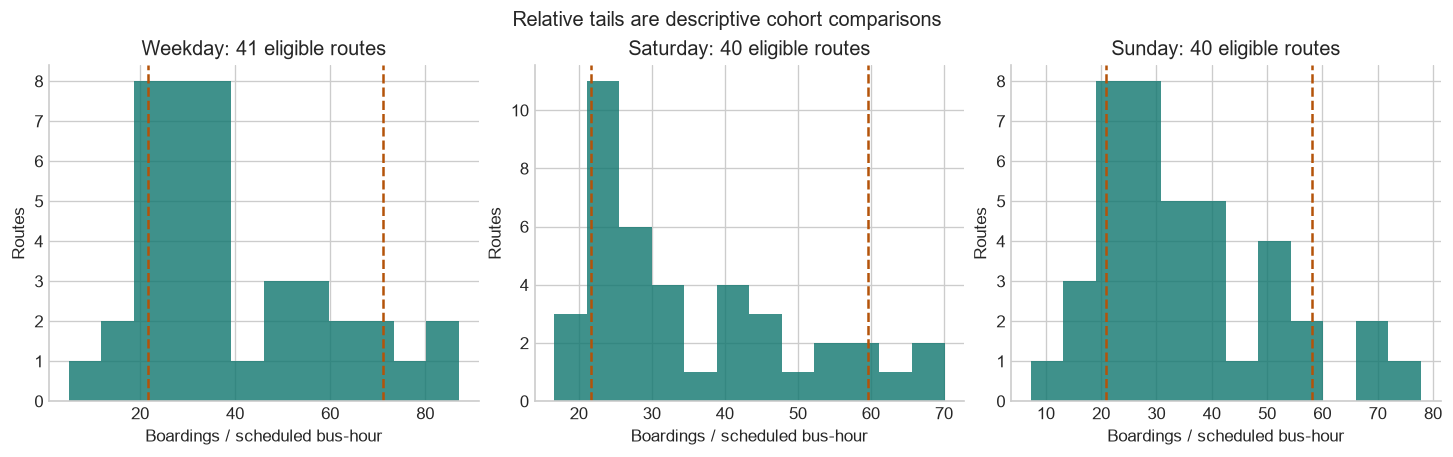

In [5]:
peer = evaluations.loc[evaluations.family.eq("relative_service_use")]
display(peer.loc[peer.triggered.fillna(False), [
    "bus_route", "day_type", "direction", "metric", "reference_metric", "cohort_routes",
    "sample_dates", "numerator_boardings", "denominator_bus_hours", "reason"]].round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, kind in zip(axes, ["Weekday", "Saturday", "Sunday"]):
    part = peer.loc[peer.day_type.eq(kind) & peer.eligible]
    ax.hist(part.metric, bins=12, color="#0f766e", alpha=.8)
    ax.axvline(part.lower_threshold.iloc[0], color="#b45309", linestyle="--")
    ax.axvline(part.upper_threshold.iloc[0], color="#b45309", linestyle="--")
    ax.set(title=f"{kind}: {len(part)} eligible routes", xlabel="Boardings / scheduled bus-hour", ylabel="Routes")
fig.suptitle("Relative tails are descriptive cohort comparisons")
fig.savefig(FIGURES / "relative_service_use.png", bbox_inches="tight")
plt.show()

## 5. Examine day-type differences and period changes

For weekends and six-week comparisons, show numerator/denominator components along with the
relative rate. School schedules, holidays and reporting differences may affect these periods,
but their causes are not identified here. A ratio is not a recommendation to change service
by the same percentage.

,bus_route,day_type,direction,metric,sample_dates,reference_dates,reason
135,M106,Saturday,lower,0.759,11,57.0,Saturday/weekday boardings-per-bus-hour ratio ...
136,M106,Sunday,lower,0.721,10,57.0,Sunday/weekday boardings-per-bus-hour ratio 0....
140,M116,Sunday,lower,0.714,10,57.0,Sunday/weekday boardings-per-bus-hour ratio 0....
144,M125,Sunday,lower,0.796,10,57.0,Sunday/weekday boardings-per-bus-hour ratio 0....
156,M20,Sunday,higher,1.269,10,57.0,Sunday/weekday boardings-per-bus-hour ratio 1....
160,M22,Sunday,lower,0.755,10,57.0,Sunday/weekday boardings-per-bus-hour ratio 0....
162,M23+,Sunday,lower,0.715,10,57.0,Sunday/weekday boardings-per-bus-hour ratio 0....
169,M34A+,Saturday,lower,0.747,11,57.0,Saturday/weekday boardings-per-bus-hour ratio ...
171,M35,Saturday,higher,4.249,11,57.0,Saturday/weekday boardings-per-bus-hour ratio ...
172,M35,Sunday,higher,1.459,10,57.0,Sunday/weekday boardings-per-bus-hour ratio 1....


,bus_route,direction,metric,early_mean_boardings,late_mean_boardings,early_mean_bus_hours,late_mean_bus_hours,sample_dates,reference_dates


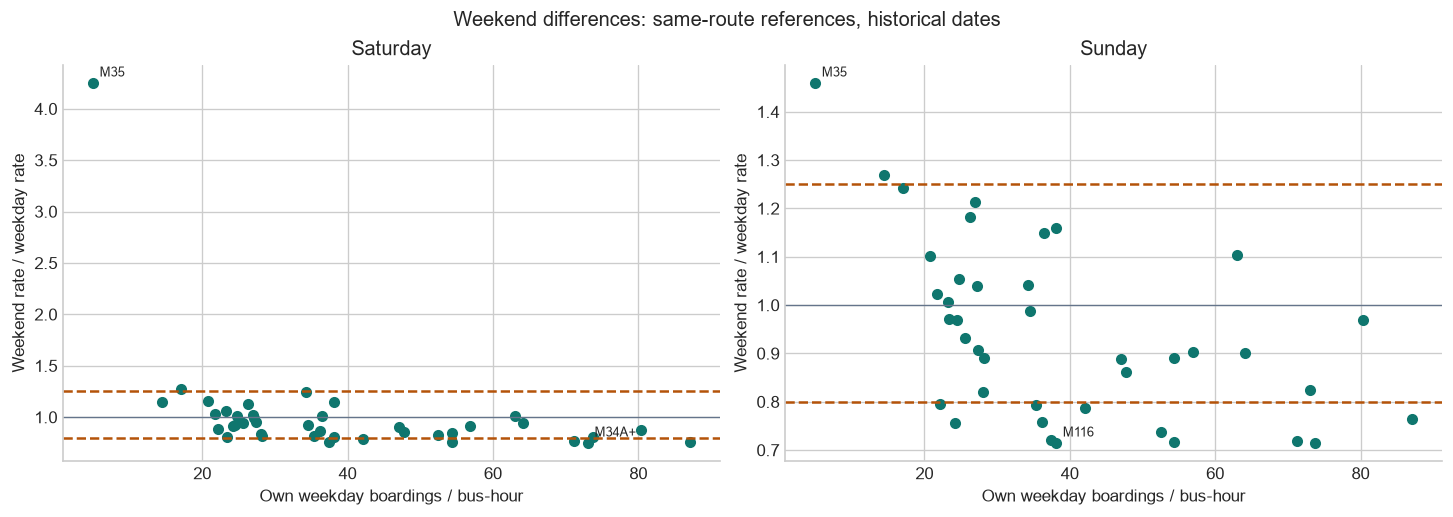

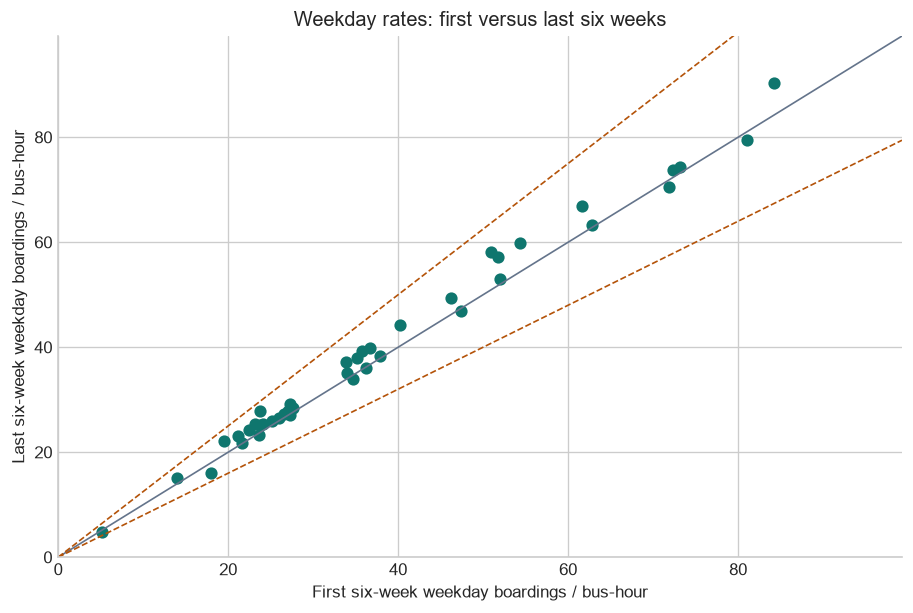

In [6]:
weekend = evaluations.loc[evaluations.family.eq("weekend_intensity_difference")]
temporal = evaluations.loc[evaluations.family.eq("weekday_intensity_change")]
display(weekend.loc[weekend.triggered.fillna(False), [
    "bus_route", "day_type", "direction", "metric", "sample_dates", "reference_dates", "reason"]].round(3))
display(temporal.loc[temporal.triggered.fillna(False), [
    "bus_route", "direction", "metric", "early_mean_boardings", "late_mean_boardings",
    "early_mean_bus_hours", "late_mean_bus_hours", "sample_dates", "reference_dates"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, kind in zip(axes, ["Saturday", "Sunday"]):
    part = weekend.loc[weekend.day_type.eq(kind) & weekend.eligible].sort_values("metric")
    ax.scatter(part.reference_metric, part.metric, color="#0f766e", s=32)
    for row in pd.concat([part.head(1), part.tail(1)]).drop_duplicates("bus_route").itertuples():
        ax.annotate(row.bus_route, (row.reference_metric, row.metric),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)
    for limit in [1 / PROTOCOL["ratio_threshold"], PROTOCOL["ratio_threshold"]]:
        ax.axhline(limit, color="#b45309", linestyle="--")
    ax.axhline(1., color="#64748b", linewidth=.8)
    ax.set(title=kind, xlabel="Own weekday boardings / bus-hour",
           ylabel="Weekend rate / weekday rate")
fig.suptitle("Weekend differences: same-route references, historical dates")
fig.savefig(FIGURES / "weekend_intensity.png", bbox_inches="tight")
plt.show()

eligible_temporal = temporal.loc[temporal.eligible].copy()
eligible_temporal["late_rate"] = eligible_temporal.metric * eligible_temporal.reference_metric
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(eligible_temporal.reference_metric, eligible_temporal.late_rate, color="#0f766e", s=40)
limit = float(max(eligible_temporal.reference_metric.max(), eligible_temporal.late_rate.max()) * 1.1)
for slope, color, style in [(1., "#64748b", "-"), (1.25, "#b45309", "--"), (.8, "#b45309", "--")]:
    ax.plot([0, limit], [0, slope * limit], color=color, linestyle=style, linewidth=1)
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="First six-week weekday boardings / bus-hour",
       ylabel="Last six-week weekday boardings / bus-hour",
       title="Weekday rates: first versus last six weeks")
fig.savefig(FIGURES / "weekday_period_change.png", bbox_inches="tight")
plt.show()

## 6. Keep grouping, corridor coverage and forecast evidence as context

Group IDs and their stability flags are optional descriptive context. Shared stops do not
justify mergers. Stop/exclusive-stop counts and overlap are specifically the September
geometry snapshot, not observations of passenger connections.

Forecast errors come from the separately labelled 14 additional October target dates.
They are not contemporaneous service-use estimates and are not inputs to any review rule.
No October forecast is compared with a July timetable to infer service need.

In [7]:
overlap = pd.read_csv(overlap_path)
directed = pd.concat([
    overlap.rename(columns={"route_a": "bus_route", "route_b": "overlap_peer",
                            "a_only_stop_ids": "own_only_stop_ids", "b_only_stop_ids": "peer_only_stop_ids"}),
    overlap.rename(columns={"route_b": "bus_route", "route_a": "overlap_peer",
                            "b_only_stop_ids": "own_only_stop_ids", "a_only_stop_ids": "peer_only_stop_ids"}),
], ignore_index=True)
top_peer = (directed.loc[directed.shared_stop_ids.gt(0)]
            .sort_values(["bus_route", "jaccard", "overlap_peer"], ascending=[True, False, True])
            .drop_duplicates("bus_route"))
context_columns = [
    "bus_route", "route_long_name", "group_id", "grouping_status", "group_membership_review",
    "bootstrap_retention", "positive_boardings_zero_service_dates", "served_stop_ids",
    "exclusive_stop_ids", "snapshot_id", "mean_template_shape_length_km",
    "mean_weekday_boardings", "mean_weekday_service_hours",
]
route_context = context[context_columns].rename(columns={"bootstrap_retention": "group_bootstrap_retention"})
route_context = route_context.merge(top_peer[["bus_route", "overlap_peer", "jaccard", "shared_stop_ids",
                                             "own_only_stop_ids", "peer_only_stop_ids"]],
                                    on="bus_route", how="left", validate="one_to_one")
route_context["review_period_start"] = members.payment_date.min()
route_context["review_period_end"] = members.payment_date.max()
route_context["common_eligible_dates"] = members.payment_date.nunique()
route_context["window_calendar_dates"] = len(pd.date_range(PROTOCOL["window_start"], PROTOCOL["window_end"]))
route_context["common_date_coverage"] = route_context.common_eligible_dates / route_context.window_calendar_dates
route_context["scheduled_source_snapshots"] = route_context.bus_route.map(
    members.groupby("bus_route").source_snapshot.agg(lambda x: "; ".join(sorted(set(x)))))

experimental_profile = json.loads((DATA / "october_validation/experimental_profile.json").read_text())
strategies = [experimental_profile["reference_strategy"], experimental_profile["challenger_strategy"]]
predictions = pd.read_csv(forecast_path, parse_dates=["payment_date"])
predictions = predictions.loc[predictions.model.isin(strategies)].copy()
assert not predictions.duplicated(["model", "bus_route", "payment_date"]).any()
forecast_rows = []
for (route, strategy), part in predictions.groupby(["bus_route", "model"]):
    error = part.prediction - part.actual
    denominator = part.actual.sum()
    forecast_rows.append({
        "bus_route": route, "strategy": strategy, "target_dates": len(part),
        "first_target_date": part.payment_date.min(), "last_target_date": part.payment_date.max(),
        "mae": error.abs().mean(), "wape": error.abs().sum() / denominator if denominator > 0 else np.nan,
        "mean_signed_error": error.mean(),
        "scope": "retrospective_additional_october_context_only", "operationally_accepted": False,
    })
forecast_context = pd.DataFrame(forecast_rows)
assert forecast_context.target_dates.eq(14).all()
for role, strategy in zip(["reference", "challenger"], strategies):
    values = forecast_context.loc[forecast_context.strategy.eq(strategy)].set_index("bus_route")
    route_context[f"forecast_{role}_mae"] = route_context.bus_route.map(values.mae)
route_context["forecast_context_dates"] = "2026-10-01 to 2026-10-04; 2026-10-12 to 2026-10-21"
route_context["forecast_context_status"] = "experimental_retrospective; prospective_validation_pending"
display(route_context[["bus_route", "group_id", "group_membership_review", "exclusive_stop_ids",
                       "overlap_peer", "jaccard"]].head(10).round(3))
display(forecast_context.head(6).round(3))
print("Context is not used to create or strengthen a planning signal.")

,bus_route,group_id,group_membership_review,exclusive_stop_ids,overlap_peer,jaccard
0,M1,G02,False,36,M2,0.426
1,M10,G01,True,78,M72,0.033
2,M101,G02,False,40,M103,0.463
3,M102,G02,False,2,M103,0.535
4,M103,G02,False,20,M102,0.535
5,M104,G01,True,42,M20,0.062
6,M106,G02,False,12,M96,0.267
7,M11,G02,False,71,M7,0.144
8,M116,G02,False,14,M7,0.128
9,M12,G01,True,22,M57,0.065


,bus_route,strategy,target_dates,first_target_date,last_target_date,mae,wape,mean_signed_error,scope,operationally_accepted
0,M1,anchored_ratio_15,14,2026-10-01,2026-10-21,582.808,0.077,-453.879,retrospective_additional_october_context_only,False
1,M1,seasonal_mean4,14,2026-10-01,2026-10-21,725.179,0.096,-416.286,retrospective_additional_october_context_only,False
2,M10,anchored_ratio_15,14,2026-10-01,2026-10-21,359.428,0.116,70.030,retrospective_additional_october_context_only,False
3,M10,seasonal_mean4,14,2026-10-01,2026-10-21,427.429,0.138,58.714,retrospective_additional_october_context_only,False
4,M101,anchored_ratio_15,14,2026-10-01,2026-10-21,1284.985,0.105,-1170.028,retrospective_additional_october_context_only,False
5,M101,seasonal_mean4,14,2026-10-01,2026-10-21,1297.393,0.106,-1085.214,retrospective_additional_october_context_only,False


Context is not used to create or strengthen a planning signal.


## 7. Test threshold sensitivity without choosing a better-looking result

Keep the primary rules unchanged. Cross tail quantiles 5%, 10%, 15% with reciprocal ratio
thresholds 1.15, 1.25, 1.50. Count supported and triggered cases under all nine settings.
These settings are alternative analyst choices, not nine independent experiments.

family,relative_service_use,weekday_intensity_change,weekend_intensity_difference
variant,,,
tail_0.05_ratio_1.15,14,1,42
tail_0.05_ratio_1.25,14,0,22
tail_0.05_ratio_1.50,14,0,1
tail_0.10_ratio_1.15,26,1,42
tail_0.10_ratio_1.25,26,0,22
tail_0.10_ratio_1.50,26,0,1
tail_0.15_ratio_1.15,38,1,42
tail_0.15_ratio_1.25,38,0,22
tail_0.15_ratio_1.50,38,0,1


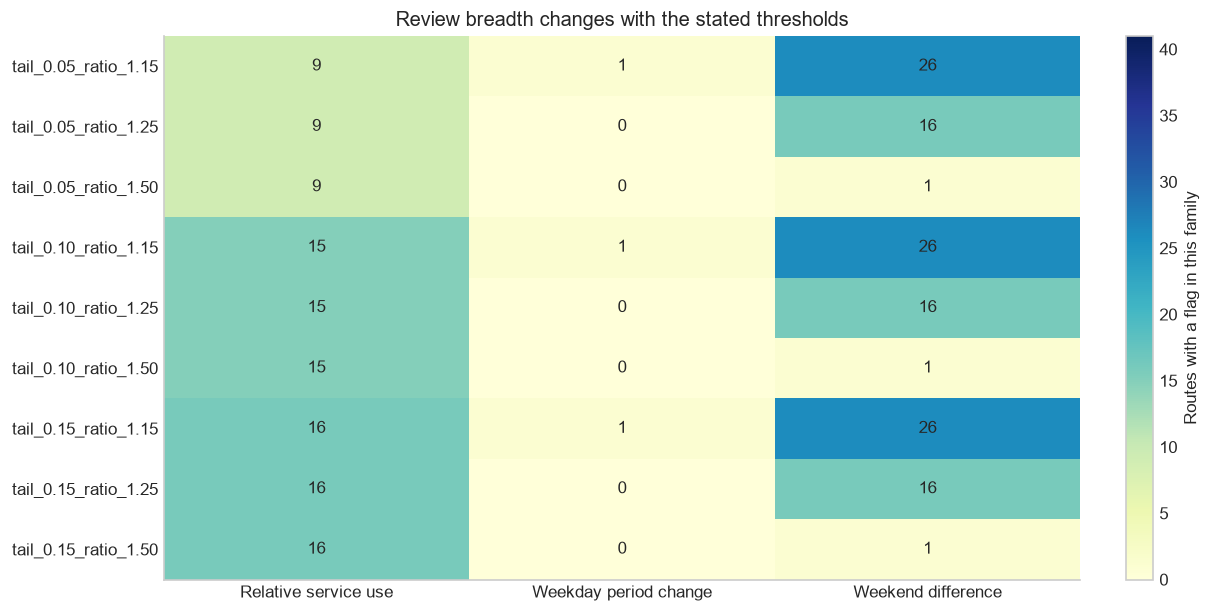

In [8]:
sensitivity_rows, sensitivity_evaluations = [], []
for tail in PROTOCOL["tail_sensitivity"]:
    for ratio in PROTOCOL["ratio_sensitivity"]:
        _, evaluated = evaluate_review_rules(
            members, tail_quantile=tail, ratio_threshold=ratio, minimum_days=PROTOCOL["minimum_days"],
            minimum_half_weekdays=PROTOCOL["minimum_half_weekdays"], minimum_cohort=PROTOCOL["minimum_cohort"])
        variant = f"tail_{tail:.2f}_ratio_{ratio:.2f}"
        sensitivity_evaluations.append(evaluated.assign(variant=variant, tail_quantile=tail, ratio_threshold=ratio))
        queue_variant = make_review_queue(evaluated, route_context)
        for family, part in evaluated.groupby("family"):
            sensitivity_rows.append({
                "variant": variant, "tail_quantile": tail, "ratio_threshold": ratio, "family": family,
                "flagged_evaluations": int(part.triggered.sum()), "eligible_evaluations": int(part.eligible.sum()),
                "flagged_routes": part.loc[part.triggered.fillna(False)].bus_route.nunique(),
                "planning_queue_routes": int(queue_variant.review_state.eq("planning_review").sum()),
                "source_clarification_routes": int(queue_variant.review_state.eq("source_clarification").sum()),
            })
sensitivity_summary = pd.DataFrame(sensitivity_rows)
sensitivity_votes = pd.concat(sensitivity_evaluations, ignore_index=True)
display(sensitivity_summary.pivot(index="variant", columns="family", values="flagged_evaluations"))
plot_counts = sensitivity_summary.pivot(index="variant", columns="family", values="flagged_routes")
fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(plot_counts, cmap="YlGnBu", aspect="auto", vmin=0, vmax=len(route_context))
ax.grid(False)
ax.set(yticks=range(len(plot_counts)), yticklabels=plot_counts.index, xticks=range(3),
       xticklabels=["Relative service use", "Weekday period change", "Weekend difference"],
       title="Review breadth changes with the stated thresholds")
for i in range(len(plot_counts)):
    for j in range(3):
        ax.text(j, i, int(plot_counts.iloc[i, j]), ha="center", va="center")
fig.colorbar(image, ax=ax, label="Routes with a flag in this family")
fig.savefig(FIGURES / "threshold_sensitivity.png", bbox_inches="tight")
plt.show()

## 8. Recompute rules under stratified whole-week resampling

Resample six whole weeks inside each six-week half, keeping routes, demand and service
together. Recompute profiles and peer thresholds on every draw. Preserving the two halves
keeps the temporal comparison meaningful. Resampled counts are weights on existing
observations, not new independent observation days.

For an original signal, report the fraction of eligible draws triggering the **same direction**.
Insufficient eligible draws remain unavailable. These frequencies describe within-window
sensitivity, not confidence that a service intervention is needed.

,repetition,unique_early_weeks,unique_late_weeks,eligible_evaluations,flagged_evaluations
count,80.000,80.000,80.000,80.0,80.000
mean,39.500,3.988,4.075,242.0,49.338
std,23.238,0.787,0.823,0.0,3.272
min,0.000,2.000,2.000,242.0,41.000
25%,19.750,3.750,4.000,242.0,47.000
50%,39.500,4.000,4.000,242.0,49.000
75%,59.250,4.250,5.000,242.0,51.000
max,79.000,6.000,6.000,242.0,58.000


,bus_route,family,day_type,direction,bootstrap_eligible_evaluations,bootstrap_retention,threshold_retention,stability_note
0,M10,relative_service_use,Weekday,lower,80,1.000,0.667,repeated_in_resampled_weeks
1,M2,relative_service_use,Weekday,lower,80,0.800,0.667,repeated_in_resampled_weeks
2,M20,relative_service_use,Weekday,lower,80,1.000,1.000,repeated_in_resampled_weeks
3,M23+,relative_service_use,Weekday,higher,80,1.000,1.000,repeated_in_resampled_weeks
4,M34+,relative_service_use,Weekday,higher,80,1.000,1.000,repeated_in_resampled_weeks
5,M34A+,relative_service_use,Weekday,higher,80,1.000,0.667,repeated_in_resampled_weeks
6,M35,relative_service_use,Weekday,lower,80,1.000,1.000,repeated_in_resampled_weeks
7,M42,relative_service_use,Weekday,higher,80,1.000,0.667,repeated_in_resampled_weeks
8,M55,relative_service_use,Weekday,lower,80,1.000,1.000,repeated_in_resampled_weeks
9,M86+,relative_service_use,Weekday,higher,80,1.000,1.000,repeated_in_resampled_weeks


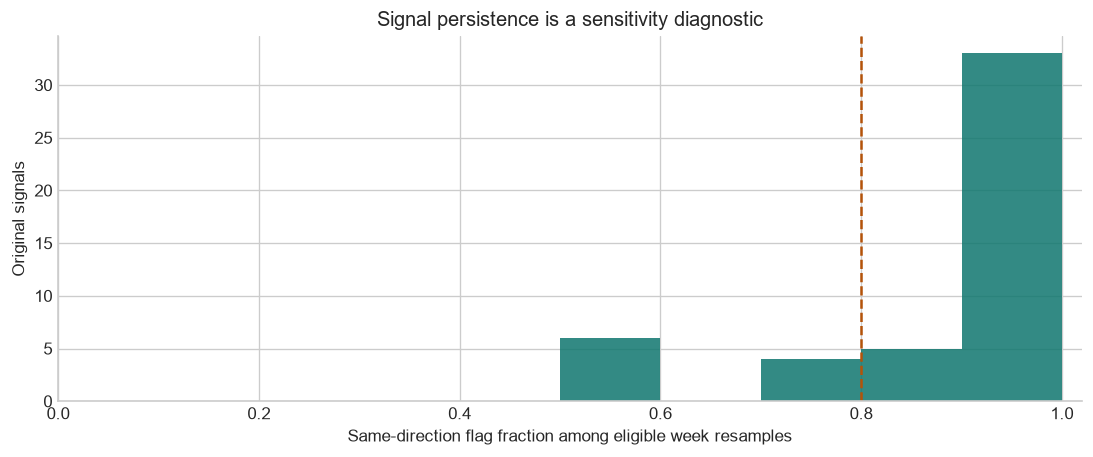

In [9]:
week_start = members.payment_date - pd.to_timedelta(members.payment_date.dt.dayofweek, unit="D")
all_blocks = [(week, part.copy()) for week, part in members.groupby(week_start)]
early_blocks = [part for week, part in all_blocks if week <= pd.Timestamp(PROTOCOL["early_end"])]
late_blocks = [part for week, part in all_blocks if week >= pd.Timestamp(PROTOCOL["late_start"])]
assert len(early_blocks) == len(late_blocks) == 6
rng = np.random.default_rng(PROTOCOL["seed"])
bootstrap_rows, bootstrap_evaluations = [], []
for repetition in range(PROTOCOL["bootstrap_repetitions"]):
    draws = [rng.integers(0, 6, size=6), rng.integers(0, 6, size=6)]
    sampled = pd.concat(
        [blocks[index] for blocks, indices in zip([early_blocks, late_blocks], draws) for index in indices],
        ignore_index=True)
    _, evaluated = evaluate_review_rules(
        sampled, tail_quantile=PROTOCOL["tail_quantile"], ratio_threshold=PROTOCOL["ratio_threshold"],
        minimum_days=PROTOCOL["bootstrap_minimum_days"],
        minimum_half_weekdays=PROTOCOL["bootstrap_minimum_half_weekdays"],
        minimum_cohort=PROTOCOL["minimum_cohort"])
    bootstrap_evaluations.append(evaluated[KEYS + ["eligible", "triggered", "direction", "metric",
        "lower_threshold", "upper_threshold", "sample_dates", "reference_dates"]].assign(repetition=repetition))
    bootstrap_rows.append({
        "repetition": repetition, "unique_early_weeks": len(set(draws[0])),
        "unique_late_weeks": len(set(draws[1])), "eligible_evaluations": int(evaluated.eligible.sum()),
        "flagged_evaluations": int(evaluated.triggered.sum()),
    })
bootstrap_runs = pd.DataFrame(bootstrap_rows)
bootstrap_votes = pd.concat(bootstrap_evaluations, ignore_index=True)
diagnostic_rows = []
for row in primary_flags.itertuples():
    diagnostics = dict(bus_route=row.bus_route, family=row.family, day_type=row.day_type)
    for prefix, frame, minimum in [
        ("bootstrap", bootstrap_votes, PROTOCOL["minimum_supported_resamples"]),
        ("threshold", sensitivity_votes, 1),
    ]:
        part = frame.loc[frame.bus_route.eq(row.bus_route) & frame.family.eq(row.family)
                         & frame.day_type.eq(row.day_type) & frame.eligible]
        successes = int((part.triggered.fillna(False) & part.direction.eq(row.direction)).sum())
        diagnostics[f"{prefix}_eligible_evaluations"] = len(part)
        diagnostics[f"{prefix}_same_direction_flags"] = successes
        diagnostics[f"{prefix}_retention"] = successes / len(part) if len(part) >= minimum else np.nan
    diagnostic_rows.append(diagnostics)
flag_diagnostics = pd.DataFrame(diagnostic_rows)
signals = primary_flags.merge(flag_diagnostics, on=KEYS, validate="one_to_one")
signals["stability_note"] = np.select(
    [signals.bootstrap_retention.isna(), signals.bootstrap_retention.lt(PROTOCOL["retention_display_threshold"])],
    ["insufficient_resampling_support", "sensitive_to_resampled_weeks"], "repeated_in_resampled_weeks")
display(bootstrap_runs.describe().round(3))
display(signals[KEYS + ["direction", "bootstrap_eligible_evaluations", "bootstrap_retention",
                        "threshold_retention", "stability_note"]].head(16).round(3))
fig, ax = plt.subplots(figsize=(9, 3.7))
ax.hist(signals.bootstrap_retention.dropna(), bins=np.linspace(0, 1, 11), color="#0f766e", alpha=.85)
ax.axvline(PROTOCOL["retention_display_threshold"], color="#b45309", linestyle="--")
ax.set(xlim=(0, 1.02), xlabel="Same-direction flag fraction among eligible week resamples",
       ylabel="Original signals", title="Signal persistence is a sensitivity diagnostic")
fig.savefig(FIGURES / "signal_resampling.png", bbox_inches="tight")
plt.show()

## 9. Assemble the route workflow and retain evidence links

Source clarification comes first, followed by insufficient evidence, planning review, and
no rule triggered. Alphabetical route order within states is only display order.
Flag counts are descriptive and are not a combined score. A source-clarification route
keeps its underlying valid observations, but does not enter the default planning queue.

,routes
review_state,
planning_review,22
no_rule_triggered,18
source_clarification,1


,bus_route,review_state,review_families,flagged_evaluations,unavailable_evaluations,common_eligible_dates,common_date_coverage
0,M98,source_clarification,,0,4,78,0.928571
1,M10,planning_review,relative_service_use,1,0,78,0.928571
2,M106,planning_review,weekend_intensity_difference,2,0,78,0.928571
3,M116,planning_review,weekend_intensity_difference,1,0,78,0.928571
4,M125,planning_review,relative_service_use; weekend_intensity_differ...,3,0,78,0.928571
5,M15+,planning_review,relative_service_use,2,0,78,0.928571
6,M2,planning_review,relative_service_use,1,0,78,0.928571
7,M20,planning_review,relative_service_use; weekend_intensity_differ...,4,0,78,0.928571
8,M22,planning_review,relative_service_use; weekend_intensity_differ...,2,0,78,0.928571
9,M23+,planning_review,relative_service_use; weekend_intensity_differ...,2,0,78,0.928571


,evidence_id,direction,metric,sample_dates,reference_dates,bootstrap_retention,threshold_retention,default_planning_queue
0,M10|relative_service_use|Weekday,lower,20.767,57,NaN,1.000,0.667,True
1,M2|relative_service_use|Weekday,lower,21.709,57,NaN,0.800,0.667,True
2,M20|relative_service_use|Weekday,lower,14.494,57,NaN,1.000,1.000,True
3,M23+|relative_service_use|Weekday,higher,73.719,57,NaN,1.000,1.000,True
4,M34+|relative_service_use|Weekday,higher,80.329,57,NaN,1.000,1.000,True
5,M34A+|relative_service_use|Weekday,higher,73.065,57,NaN,1.000,0.667,True
6,M35|relative_service_use|Weekday,lower,4.978,57,NaN,1.000,1.000,True
7,M42|relative_service_use|Weekday,higher,71.218,57,NaN,1.000,0.667,True
8,M55|relative_service_use|Weekday,lower,17.037,57,NaN,1.000,1.000,True
9,M86+|relative_service_use|Weekday,higher,87.104,57,NaN,1.000,1.000,True


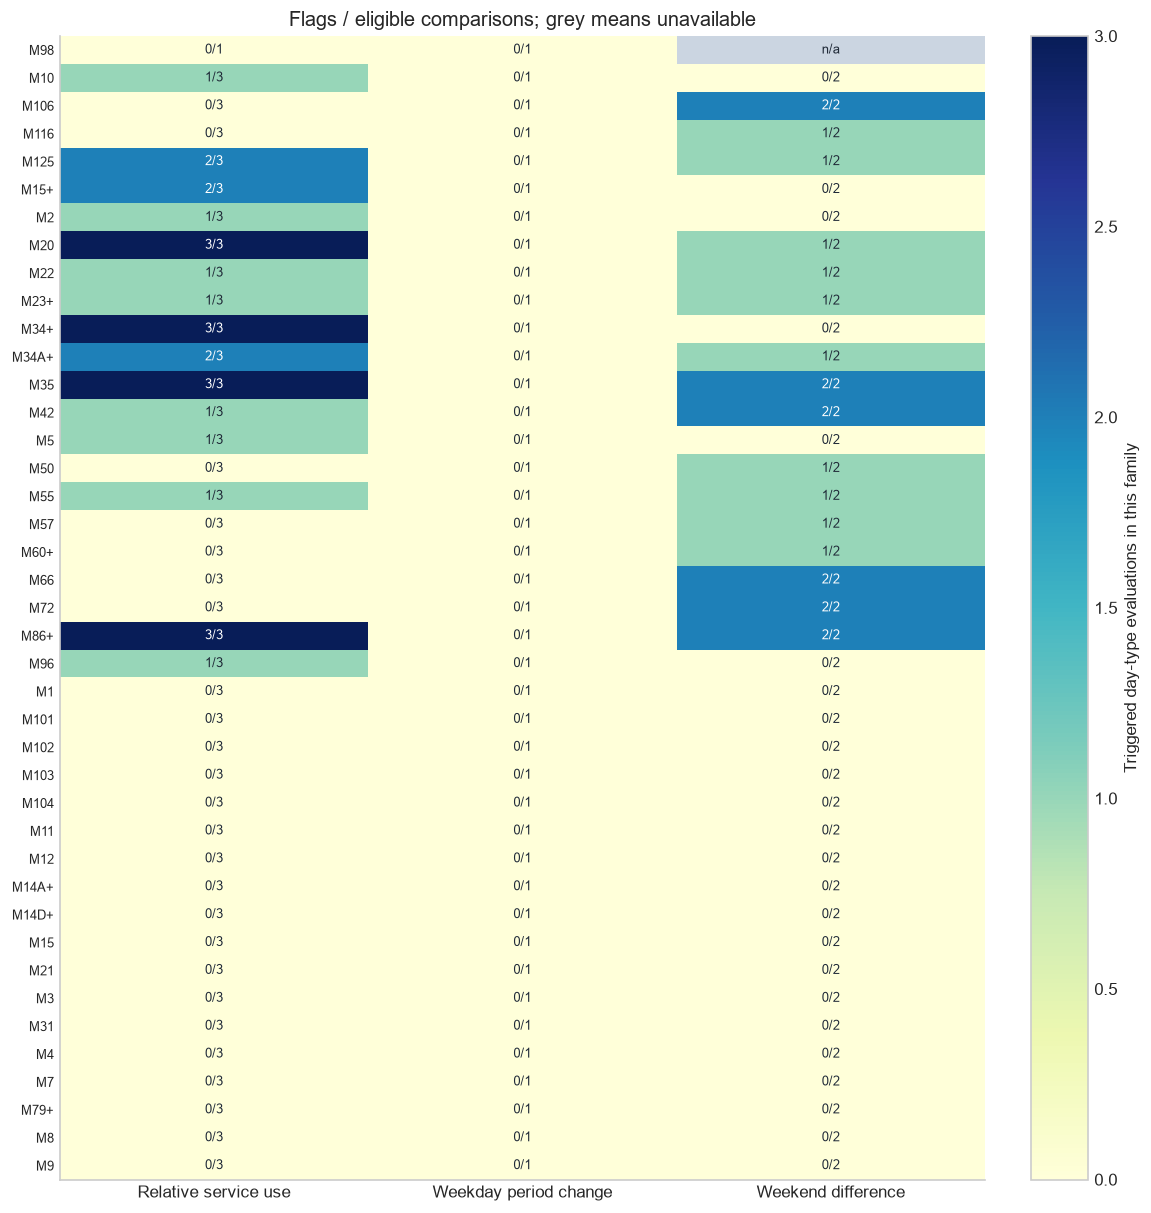

In [10]:
queue = make_review_queue(evaluations, route_context)
source_queue = queue.loc[queue.review_state.eq("source_clarification")].copy()
planning_queue = queue.loc[queue.review_state.eq("planning_review")].copy()
signals = signals.merge(queue[["bus_route", "review_state"]], on="bus_route", validate="many_to_one")
signals["default_planning_queue"] = signals.review_state.eq("planning_review")
signals["evidence_id"] = signals[KEYS].astype(str).agg("|".join, axis=1)
queue["review_evidence_ids"] = queue.bus_route.map(
    signals.groupby("bus_route").evidence_id.agg(lambda x: "; ".join(x))).fillna("")
queue["source_evidence_ids"] = queue.bus_route.map(
    source_issues.groupby("bus_route").evidence_id.agg(lambda x: "; ".join(x))).fillna("")
source_queue = queue.loc[queue.review_state.eq("source_clarification")].copy()
planning_queue = queue.loc[queue.review_state.eq("planning_review")].copy()
display(queue.review_state.value_counts().rename("routes").to_frame())
display(queue[["bus_route", "review_state", "review_families", "flagged_evaluations",
               "unavailable_evaluations", "common_eligible_dates", "common_date_coverage"]])
display(signals[["evidence_id", "direction", "metric", "sample_dates", "reference_dates",
                 "bootstrap_retention", "threshold_retention", "default_planning_queue"]].head(18).round(3))
family_grid = (evaluations.assign(flag=evaluations.triggered.fillna(False).astype(int))
               .pivot_table(index="bus_route", columns="family", values="flag", aggfunc="sum")
               .reindex(queue.bus_route))
eligible_grid = evaluations.pivot_table(
    index="bus_route", columns="family", values="eligible", aggfunc="sum").reindex(queue.bus_route)
display_grid = family_grid.where(eligible_grid.gt(0))
fig, ax = plt.subplots(figsize=(9.5, 10))
color_map = plt.get_cmap("YlGnBu").copy()
color_map.set_bad("#cbd5e1")
image = ax.imshow(display_grid, cmap=color_map, aspect="auto", vmin=0, vmax=3)
ax.grid(False)
ax.set(yticks=range(len(queue)), yticklabels=queue.bus_route, xticks=range(3),
       xticklabels=["Relative service use", "Weekday period change", "Weekend difference"],
       title="Flags / eligible comparisons; grey means unavailable")
ax.tick_params(axis="y", labelsize=8)
for i in range(len(queue)):
    for j in range(3):
        count = int(eligible_grid.iloc[i, j])
        label = f"{int(family_grid.iloc[i, j])}/{count}" if count else "n/a"
        ax.text(j, i, label, ha="center", va="center", fontsize=8,
                color="white" if count and family_grid.iloc[i, j] >= 2 else "#1f2937")
fig.colorbar(image, ax=ax, label="Triggered day-type evaluations in this family")
fig.savefig(FIGURES / "route_evidence_grid.png", bbox_inches="tight")
plt.show()

## 10. Inspect concrete cases and define follow-up

Investigate source questions before interpreting affected rates. For relative service-use
signals, examine coverage purpose, capacity and passenger journeys. For weekend or temporal
differences, inspect the actual timetable, operating constraints and additional observation
periods. Do not infer actual delays, crowding, unnecessary service or benefits from changing trips.

In [11]:
examples = (signals.sort_values(["family", "day_type", "bus_route"])
            .groupby("family", as_index=False).head(2))
display(examples[["bus_route", "family", "day_type", "direction", "reason",
                  "first_date", "last_date", "reference_first_date", "reference_last_date",
                  "numerator_boardings", "denominator_bus_hours",
                  "bootstrap_retention", "threshold_retention"]].round(3))
display(source_summary)
no_signal = queue.loc[queue.review_state.eq("no_rule_triggered")]
print("No rule triggered is a statement about these rules and dates, not a balanced-service label.")
print("No-rule routes:", ", ".join(no_signal.bus_route) if len(no_signal) else "None under the primary thresholds")
state_counts = queue.review_state.value_counts().to_dict()
interpretation = (
    f"**Historical review workflow:** {len(queue)} routes; "
    f"{state_counts.get('source_clarification', 0)} source-clarification, "
    f"{state_counts.get('planning_review', 0)} planning-review, "
    f"{state_counts.get('no_rule_triggered', 0)} no-rule and "
    f"{state_counts.get('insufficient_evidence', 0)} insufficient-evidence routes. "
    f"{len(signals)} primary triggered evaluations remain available with their reasons, dates "
    f"and denominators. {int(signals.bootstrap_retention.lt(.8).sum())} signals are sensitive "
    "to resampled weeks under the stated display threshold.\n\n"
    "These are historical screening results, not current operational conditions. "
    f"The nine threshold choices yield {sensitivity_summary.planning_queue_routes.min()}–"
    f"{sensitivity_summary.planning_queue_routes.max()} planning-review routes. "
    f"The primary weekday-change rule triggers {int(temporal.triggered.sum())} cases. "
    "Signal counts are not a performance score. "
    "Clustering, overlap and later forecast diagnostics are context only. "
    "Any proposed service change needs a separate scenario and operational evidence."
)
display(Markdown(interpretation))

,bus_route,family,day_type,direction,reason,first_date,...,reference_first_date,reference_last_date,numerator_boardings,denominator_bus_hours,bootstrap_retention,threshold_retention
10,M125,relative_service_use,Saturday,lower,19.56 boardings/bus-hour; Saturday cohort medi...,2026-07-11,...,2026-07-11,2026-09-26,30771.0,1573.183,0.975,0.667
11,M15+,relative_service_use,Saturday,higher,63.69 boardings/bus-hour; Saturday cohort medi...,2026-07-11,...,2026-07-11,2026-09-26,169428.0,2660.350,1.000,0.667
26,M106,weekend_intensity_difference,Saturday,lower,Saturday/weekday boardings-per-bus-hour ratio ...,2026-07-11,...,2026-07-06,2026-09-25,4665.0,164.267,0.850,0.667
33,M34A+,weekend_intensity_difference,Saturday,lower,Saturday/weekday boardings-per-bus-hour ratio ...,2026-07-11,...,2026-07-06,2026-09-25,27117.0,497.017,1.000,0.667


,bus_route,day_type,affected_dates,first_date,last_date,published_boardings,required_follow_up
0,M98,Saturday,3,2026-07-18,2026-09-12,15.0,"Verify source route identity, calendar service..."
1,M98,Sunday,1,2026-07-19,2026-07-19,4.0,"Verify source route identity, calendar service..."


No rule triggered is a statement about these rules and dates, not a balanced-service label.
No-rule routes: M1, M101, M102, M103, M104, M11, M12, M14A+, M14D+, M15, M21, M3, M31, M4, M7, M79+, M8, M9


**Historical review workflow:** 41 routes; 1 source-clarification, 22 planning-review, 18 no-rule and 0 insufficient-evidence routes. 48 primary triggered evaluations remain available with their reasons, dates and denominators. 10 signals are sensitive to resampled weeks under the stated display threshold.

These are historical screening results, not current operational conditions. The nine threshold choices yield 9–31 planning-review routes. The primary weekday-change rule triggers 0 cases. Signal counts are not a performance score. Clustering, overlap and later forecast diagnostics are context only. Any proposed service change needs a separate scenario and operational evidence.

## 11. Save the review tables and verify earlier work is intact

The manifest records inputs, code, protocol, runtime and product fingerprints. All candidate
evaluations, including unavailable and nontriggered rows, are retained. Forecast registrations
remain unchanged. Exported queues provide review suggestions without automated actions.

In [12]:
import nbformat

tables = {
    "route_day_type_evidence": profiles, "rule_evaluations": evaluations,
    "review_signals": signals, "route_review_table": queue, "planning_review_queue": planning_queue,
    "source_clarification_queue": source_queue, "source_issue_dates": source_issues,
    "source_issue_summary": source_summary, "route_context": route_context,
    "forecast_context": forecast_context, "threshold_sensitivity_summary": sensitivity_summary,
    "threshold_evaluations": sensitivity_votes, "bootstrap_runs": bootstrap_runs,
    "bootstrap_evaluations": bootstrap_votes, "signal_diagnostics": flag_diagnostics,
}
products = {}
for name, frame in tables.items():
    path = OUT / f"{name}.csv"
    frame.to_csv(path, index=False)
    products[path.relative_to(ROOT).as_posix()] = {
        "sha256": sha256(path), "rows": len(frame), "columns": frame.columns.tolist()}
for path in sorted(FIGURES.glob("*.png")):
    products[path.relative_to(ROOT).as_posix()] = {"sha256": sha256(path)}
for relative, expected in protected_before.items():
    assert sha256(ROOT / relative) == expected, relative
notebook = nbformat.read(ROOT / "notebooks/new_york/10_explainable_route_review.ipynb", as_version=4)
code_source = "\n\n".join(c.source for c in notebook.cells if c.cell_type == "code")
manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(), "scope": "historical_descriptive_review",
    "protocol": PROTOCOL, "routes": sorted(queue.bus_route), "member_route_dates": len(members),
    "common_dates": members.payment_date.nunique(), "state_counts": state_counts,
    "rule_evaluations": len(evaluations), "triggered_evaluations": len(signals),
    "sensitive_to_resampled_weeks": int(signals.bootstrap_retention.lt(.8).sum()),
    "input_files": input_hashes, "source_code": {"scripts/route_review.py": sha256(ROOT / "scripts/route_review.py")},
    "notebook_code_sha256": hashlib.sha256(code_source.encode()).hexdigest(),
    "products": products, "protected_original_files": protected_before,
    "runtime": {"python": platform.python_version(), **{
        name: importlib.metadata.version(name) for name in ["numpy", "pandas", "matplotlib"]}},
    "ranking_uses_cluster_labels": False, "ranking_uses_forecasts": False,
    "automated_service_change": False, "crowding_labels_available": False,
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(REPORT / "FINDINGS.md").write_text("# Explainable route review\n\n" + interpretation,
                                   encoding="utf-8")
print("Saved tables:", len(tables), "| Figures:", len(list(FIGURES.glob("*.png"))))
print("Earlier artifacts unchanged:", len(protected_before))
print("Products:", OUT.relative_to(ROOT).as_posix())
print("Independent check: python scripts/audit_route_review.py")

Saved tables: 15 | Figures: 6
Earlier artifacts unchanged: 174
Products: data/processed/new_york/route_review
Independent check: python scripts/audit_route_review.py


## Interpretation and next use

Use the full route table together with its keyed signal evidence, source issues, sample support
and threshold/resampling diagnostics. The default planning queue excludes source-clarification
routes; it does not delete their evidence.

The next milestone is **explicit frequency-scenario arithmetic** with matched baseline service,
clearly stated fixed-demand assumptions and no claim of measured passenger or operational benefit.
The Streamlit interface remains a separate milestone.